# Linear models (OLS, Ridge, Lasso)

Target: `final_grade_pct` (regression). This notebook loads the prepared train/test data saved by `Project.ipynb`, so run that notebook first.

Every model is evaluated on the same 10 outer folds of the training set, using the predictors kept by the Lasso selection step. Each model is fit on the outer training folds, and its validation RMSE is recorded. It is then refitted on all training rows and scored once on the test set. A mean-only baseline is included as a reference.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path('prepared_data')
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)

with open(DATA_DIR / 'meta.json') as f:
    meta = json.load(f)

SEED = meta['seed']
N_SPLITS = meta['n_splits']
PREDICTOR_COLS = meta['predictor_cols']
NUMERIC_COLS = meta['numeric_cols']

X_train_final = pd.read_csv(DATA_DIR / 'X_train.csv', index_col=0)
X_test_final = pd.read_csv(DATA_DIR / 'X_test.csv', index_col=0)
Y_train = pd.read_csv(DATA_DIR / 'Y_train.csv', index_col=0)[meta['target']]
Y_test = pd.read_csv(DATA_DIR / 'Y_test.csv', index_col=0)[meta['target']]
print('train:', X_train_final.shape, ' test:', X_test_final.shape)

train: (10200, 17)  test: (1800, 17)


## Shared setup and mean-only baseline

In [2]:
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

MODEL_COLS = list(X_train_final.columns)
ALPHA_GRID = np.logspace(-4, 1, 60)
RIDGE_GRID = np.logspace(-3, 3, 50)
inner_cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
outer_folds = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train_final))


def source_variable(col):
    # Maps a one-hot column back to its raw predictor name
    for raw in PREDICTOR_COLS:
        if col == raw or col.startswith(raw + '_'):
            return raw
    return col


def run_group(factories):
    # factories maps a model name to a function that returns a fresh, unfitted model
    cv_fold_rmse = {name: [] for name in factories}
    for fold, (train_idx, valid_idx) in enumerate(outer_folds, start=1):
        X_tr, X_valid = X_train_final.iloc[train_idx], X_train_final.iloc[valid_idx]
        Y_tr, Y_valid = Y_train.iloc[train_idx], Y_train.iloc[valid_idx]
        for name, make in factories.items():
            model = make().fit(X_tr, Y_tr)
            cv_fold_rmse[name].append(root_mean_squared_error(Y_valid, model.predict(X_valid)))
        print(f'Finished outer fold {fold}/{len(outer_folds)}')

    fitted, rows = {}, []
    for name, make in factories.items():
        model = make().fit(X_train_final, Y_train)
        if isinstance(model, GridSearchCV):
            print(f'{name} selected on all training rows: {model.best_params_}')
            fitted[name] = model.best_estimator_
        else:
            fitted[name] = model
        rows.append({
            'model': name,
            'cv_rmse': np.mean(cv_fold_rmse[name]),
            'cv_rmse_sd': np.std(cv_fold_rmse[name], ddof=1),
            'test_rmse': root_mean_squared_error(Y_test, model.predict(X_test_final)),
        })
    table = pd.DataFrame(rows).set_index('model')
    print(table.round(3).to_string())
    return {'cv_fold_rmse': cv_fold_rmse, 'fitted': fitted, 'table': table}


def scaled_model(cols, estimator):
    scale_cols = [c for c in cols if source_variable(c) in NUMERIC_COLS]
    scaling = ColumnTransformer([('scale', StandardScaler(), scale_cols)],
                                remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(scaling.set_output(transform='pandas'), estimator)


baseline_results = run_group({'Mean only (baseline)': lambda: DummyRegressor(strategy='mean')})

Finished outer fold 1/10
Finished outer fold 2/10
Finished outer fold 3/10
Finished outer fold 4/10
Finished outer fold 5/10
Finished outer fold 6/10
Finished outer fold 7/10
Finished outer fold 8/10
Finished outer fold 9/10
Finished outer fold 10/10
                      cv_rmse  cv_rmse_sd  test_rmse
model                                               
Mean only (baseline)   11.695       0.134     11.708


### Linear models (OLS, Ridge, Lasso)

Ridge and Lasso are standardized inside each fold, and their penalties are chosen by the inner 10-fold CV. OLS uses the same scaling so the three share one pipeline shape.

Finished outer fold 1/10


Finished outer fold 2/10


Finished outer fold 3/10


Finished outer fold 4/10


Finished outer fold 5/10


...

Finished outer fold 8/10


Finished outer fold 9/10


Finished outer fold 10/10


Ridge selected on all training rows: {'ridge__alpha': np.float64(10.985411419875572)}


Lasso selected on all training rows: {'lasso__alpha': np.float64(0.0001)}
       cv_rmse  cv_rmse_sd  test_rmse
model                                
OLS      9.629       0.313      9.834
Ridge    9.629       0.312      9.835
Lasso    9.629       0.313      9.834


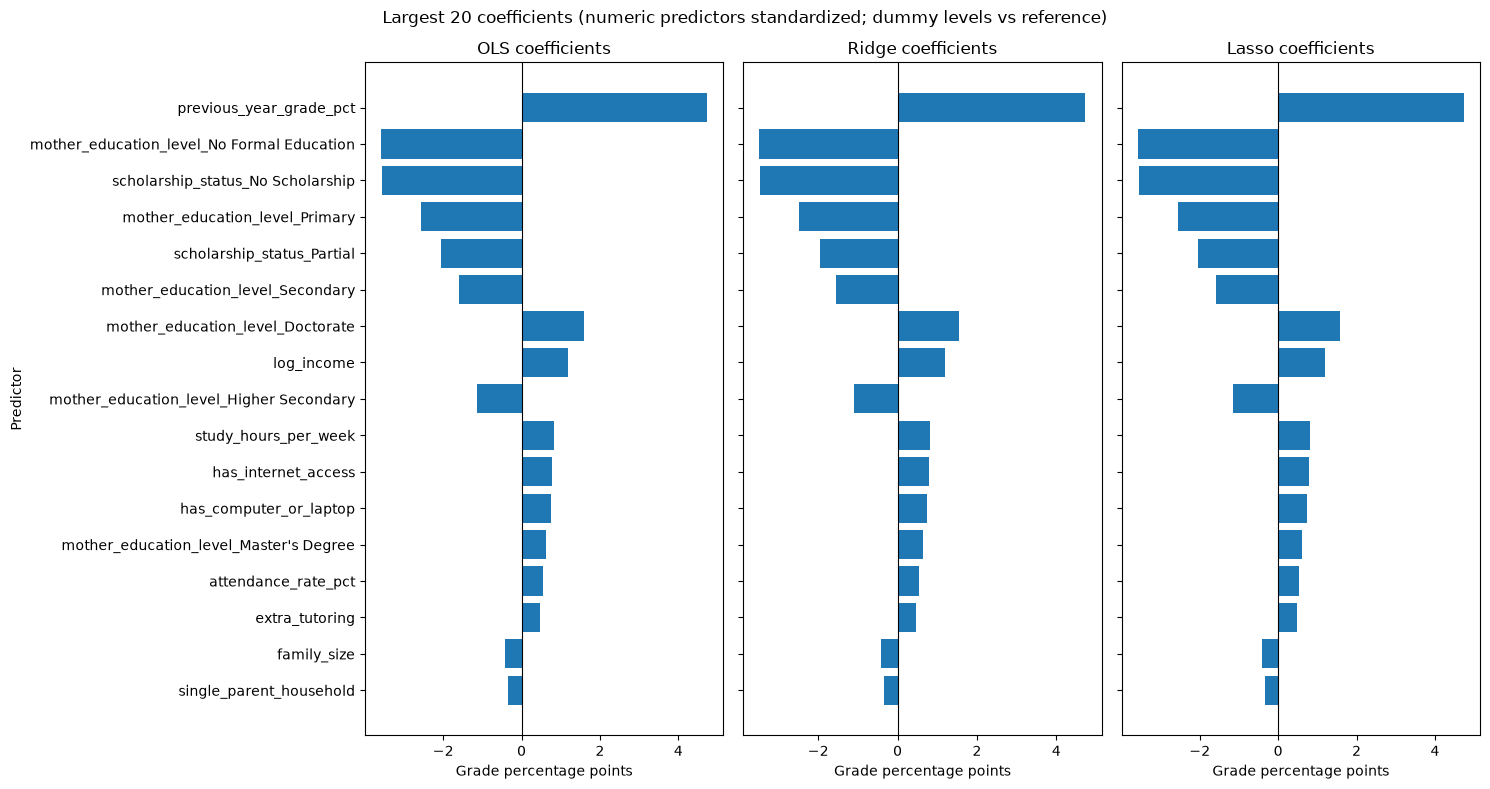

In [3]:
def tune_ridge():
    return GridSearchCV(scaled_model(MODEL_COLS, Ridge()), {'ridge__alpha': RIDGE_GRID},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


def tune_lasso():
    return GridSearchCV(scaled_model(MODEL_COLS, Lasso(max_iter=20000)), {'lasso__alpha': ALPHA_GRID},
                        cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)


linear_results = run_group({
    'OLS': lambda: scaled_model(MODEL_COLS, LinearRegression()),
    'Ridge': tune_ridge,
    'Lasso': tune_lasso,
})

coef_series = {}
for name in ['OLS', 'Ridge', 'Lasso']:
    fitted = linear_results['fitted'][name]
    coef_series[name] = pd.Series(fitted[-1].coef_, index=fitted[:-1].get_feature_names_out())

largest = pd.concat(coef_series, axis=1).abs().max(axis=1)
feature_order = largest.nlargest(min(20, len(largest))).sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(15, 8), sharey=True)
for ax, name in zip(axes, ['OLS', 'Ridge', 'Lasso']):
    ax.barh(feature_order, coef_series[name].loc[feature_order])
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{name} coefficients')
    ax.set_xlabel('Grade percentage points')
axes[0].set_ylabel('Predictor')
fig.suptitle('Largest 20 coefficients (numeric predictors standardized; dummy levels vs reference)')
plt.tight_layout()
plt.show()

### Save results

The fold-level errors are saved so `Project-Trees.ipynb` can run its paired tests against OLS and the baseline on the same outer folds.

In [4]:
saved = {'cv_fold_rmse': {**baseline_results['cv_fold_rmse'], **linear_results['cv_fold_rmse']},
         'table': {**baseline_results['table'].to_dict(orient='index'),
                   **linear_results['table'].to_dict(orient='index')}}
with open(RESULTS_DIR / 'linear.json', 'w') as f:
    json.dump(saved, f, indent=2)

linear_table = pd.concat([baseline_results['table'], linear_results['table']])
print(linear_table.round(3).to_string())

for left, right in [('Mean only (baseline)', 'OLS'), ('OLS', 'Ridge'), ('OLS', 'Lasso')]:
    p_value = ttest_rel(saved['cv_fold_rmse'][left], saved['cv_fold_rmse'][right]).pvalue
    print(f'Paired t-test, {left} vs {right} (exploratory): p = {p_value:.4g}')

                      cv_rmse  cv_rmse_sd  test_rmse
model                                               
Mean only (baseline)   11.695       0.134     11.708
OLS                     9.629       0.313      9.834
Ridge                   9.629       0.312      9.835
Lasso                   9.629       0.313      9.834
Paired t-test, Mean only (baseline) vs OLS (exploratory): p = 6.295e-10
Paired t-test, OLS vs Ridge (exploratory): p = 0.7555
Paired t-test, OLS vs Lasso (exploratory): p = 0.4578


## Conclusion

The linear models clearly beat the mean-only baseline and are statistically tied with each other.

- **Predictors help.** The mean-only baseline has CV RMSE 11.70. OLS, Ridge and Lasso reach 9.63, a reduction of about 18%, with paired p ≈ 6e-10.
- **Linear models are tied.** OLS, Ridge and Lasso all have CV RMSE 9.63 and fold SD about 0.31. OLS vs Ridge has p = 0.76 and OLS vs Lasso p = 0.46. Ridge's selected penalty (alpha about 11) barely changes the coefficients. The CV-selected Lasso penalty sits at the smallest value on the grid (0.0001), so Lasso is effectively OLS here.
- **Test set agrees.** Refitted on all training rows and scored once on the 1,800-row test set: mean only 11.71, OLS/Ridge/Lasso 9.83.

**Interpretation.** Previous-year grade, log income, and scholarship status have the largest coefficients, and study hours, internet and computer access, and attendance follow. The tuned penalties do almost nothing, so the signal is close to linear and additive, with little to gain from shrinkage at this sample size.

The tree models are compared against these results in `Project-Trees.ipynb`.